In [ ]:
!pip install -q idc-index

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.2/79.2 MB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 75.3 MB/s eta 0:00:00


In [ ]:
import time
from idc_index import IDCClient

t = time.time()
IDCClient().download_from_selection(
    downloadDir="/content/raw",
    collection_id="lung_pet_ct_dx",
    patientId="Lung_Dx-A0001",
)
print("sekundy:", round(time.time() - t, 1))

sekundy: 7.7


In [7]:
from google.colab import drive
drive.mount("/content/drive")

import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/lung-ct/annotations.csv")
print(len(df), df["patient"].nunique())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
31659 357


In [5]:
import os
print(os.listdir("/content/drive/MyDrive"))

['IP_QoS_Inzynieria ruchu.project.zip', 'Colab Notebooks', 'machinelearningwithpythoncookbook_secondedition_V5.pdf', 'developersplaybookforlargelanguagemodelsecurity.pdf', 'low-codeai_V4.pdf', 'hands-ongenerativeaiwithtransformersanddiffusionmodels.pdf', 'developersplaybookforlargelanguagemodelsecurity (1).pdf', 'machinelearninginterviews.pdf', 'hands-onlargelanguagemodels.pdf', 'low-codeai_V4 (1).pdf', 'generativedeeplearning_secondedition_V4.pdf', 'promptengineeringforgenerativeai.pdf', 'hands-onlargelanguagemodels (1).pdf', 'machinelearninginterviews (1).pdf', 'developersplaybookforlargelanguagemodelsecurity (2).pdf', 'developingappswithgpt-4andchatgpt.pdf', 'promptengineeringforllms.pdf', 'naturallanguageprocessingwithtransformersrevisededition.pdf', 'architectingdataandmachinelearningplatforms.pdf', 'PDF 130625 8.20.33.pdf', 'Folder bez nazwy', 'Dokument bez tytułu.gdoc', 'WdTB_Spring.pptx', 'Java Persistence API WSB Wyklad 2.pptx', 'Java Persistence API WSB Wyklad 1.pptx', 'Activ

In [6]:
print(os.listdir("/content/drive/MyDrive/lung-ct"))

['Annotation']


In [11]:
import numpy as np, pandas as pd, pydicom, shutil
from pathlib import Path
from idc_index import IDCClient

client = IDCClient()
idx = client.index
ct_idx = idx[(idx["collection_id"] == "lung_pet_ct_dx") & (idx["Modality"] == "CT")]

OUT = Path("/content/drive/MyDrive/lung-ct/crops")
OUT.mkdir(parents=True, exist_ok=True)
RAW = Path("/content/raw")
PAD = 32

by_sop = {}
for r in df.itertuples():
    by_sop.setdefault(r.sop_uid, []).append(r)

def process_patient(pid):
    if (OUT / f"{pid}.npz").exists():
        return None
    series = ct_idx[ct_idx["PatientID"] == "Lung_Dx-" + pid]["SeriesInstanceUID"].tolist()
    shutil.rmtree(RAW, ignore_errors=True)
    client.download_from_selection(downloadDir=str(RAW), seriesInstanceUID=series, quiet=True)
    crops, meta = {}, []
    for f in RAW.rglob("*.dcm"):
        ds = pydicom.dcmread(f)
        uid = ds.SOPInstanceUID
        if uid not in by_sop:
            continue
        hu = ds.pixel_array.astype(np.float32) * float(ds.RescaleSlope) + float(ds.RescaleIntercept)
        for r in by_sop[uid]:
            x0, y0 = max(r.xmin - PAD, 0), max(r.ymin - PAD, 0)
            x1, y1 = min(r.xmax + PAD, hu.shape[1]), min(r.ymax + PAD, hu.shape[0])
            key = f"{uid}_{r.obj_idx}_{r.patient}"
            crops[key] = hu[y0:y1, x0:x1].astype(np.int16)
            meta.append(dict(key=key, xml_patient=r.patient, dicom_patient=pid, cls=r.cls,
                             obj_idx=r.obj_idx, sop_uid=uid, xmin=r.xmin, ymin=r.ymin,
                             xmax=r.xmax, ymax=r.ymax, x0=x0, y0=y0,
                             series_uid=ds.SeriesInstanceUID,
                             series_desc=str(ds.get("SeriesDescription", "")),
                             slice_loc=float(ds.get("SliceLocation", "nan")),
                             inst_no=int(ds.get("InstanceNumber", -1))))
    np.savez_compressed(OUT / f"{pid}.npz", **crops)
    pd.DataFrame(meta).to_csv(OUT / f"{pid}.csv", index=False)
    shutil.rmtree(RAW, ignore_errors=True)
    return len(meta)

n = process_patient("A0001")
print("wycięto:", n, "| w CSV dla A0001:", (df["patient"] == "A0001").sum())

wycięto: 20 | w CSV dla A0001: 20


In [10]:
!pip install -q pydicom

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 62.6 MB/s eta 0:00:00


In [12]:
import time
patients = sorted(df["patient"].unique())
errors = []
t0 = time.time()
for i, pid in enumerate(patients):
    try:
        n = process_patient(pid)
    except Exception as e:
        errors.append((pid, repr(e)))
        print("BŁĄD", pid, repr(e)[:150])
        continue
    if n is not None:
        print(f"{i+1}/{len(patients)} {pid}: {n} obiektów ({time.time()-t0:.0f}s)")
print("koniec, błędy:", errors)

2/357 A0002: 18 obiektów (1s)


3/357 A0003: 10 obiektów (2s)


4/357 A0004: 9 obiektów (3s)


5/357 A0005: 2 obiektów (4s)


6/357 A0006: 17 obiektów (6s)


...

BŁĄD G0057 AttributeError("'FileDataset' object has no attribute 'RescaleSlope'")


BŁĄD G0058 AttributeError("'FileDataset' object has no attribute 'RescaleSlope'")


BŁĄD G0059 AttributeError("'FileDataset' object has no attribute 'RescaleSlope'")


BŁĄD G0060 AttributeError("'FileDataset' object has no attribute 'RescaleSlope'")


BŁĄD G0062 AttributeError("'FileDataset' object has no attribute 'RescaleSlope'")
koniec, błędy: [('A0060', "ValueError('No data found for the SeriesInstanceUID with the values [].')"), ('A0067', "ValueError('No data found for the SeriesInstanceUID with the values [].')"), ('A0076', "ValueError('No data found for the SeriesInstanceUID with the values [].')"), ('A0164', 'AttributeError("\'FileDataset\' object has no attribute \'RescaleSlope\'")'), ('A0165', 'AttributeError("\'FileDataset\' object has no attribute \'RescaleSlope\'")'), ('A0166', 'AttributeError("\'FileDataset\' object has no attribute \'RescaleSlope\'")'), ('A0167', 'AttributeError("\'FileDataset\' object has no attribute \'RescaleSlope\'")'), ('A0168', 'AttributeError("\'FileDataset\' object has no attribute \'RescaleSlope\'")'), ('A0169', 'AttributeError("\'FileDataset\' object has no attribute \'RescaleSlope\'")'), ('A0170', 'AttributeError("\'FileDataset\' object has no attribute \'RescaleSlope\'")'), ('A0171', 'Attr

In [15]:
from collections import Counter
bad = Counter()
ok = Counter()
example = None
for f in RAW.rglob("*.dcm"):
    ds = pydicom.dcmread(f, stop_before_pixels=True)
    if ds.SOPInstanceUID not in by_sop:
        continue
    key = (f.parent.name[:12], str(ds.get("SeriesDescription")))
    if "RescaleSlope" in ds:
        ok[key] += 1
    else:
        bad[key] += 1
        example = example or f
print("OK:", ok)
print("BRAK:", bad)
if example:
    ds = pydicom.dcmread(example)
    print(ds.get("Modality"), ds.get("SOPClassUID"), ds.get("ImageType"))
    print(ds.dir("Rescale"), ds.get("PixelRepresentation"), ds.get("BitsStored"))

OK: Counter()
BRAK: Counter({('CT_1.3.6.1.4', 'Range-CT WB  1.0  B30f-Tra-<ALPHA Range>'): 30})
CT 1.2.840.10008.5.1.4.1.1.7 ['DERIVED', 'SECONDARY', 'OTHER', 'CSA FUSED MPR', '', 'CSAPARALLEL', 'AXIAL', 'CT_SOM5 SPI']
[] 0 8


In [17]:
rows = []
for d in sorted(p for p in RAW.rglob("CT_*") if p.is_dir()):
    n = n_ann = n_resc = 0
    desc = cls = ""
    for f in d.glob("*.dcm"):
        ds = pydicom.dcmread(f, stop_before_pixels=True)
        n += 1
        desc, cls = str(ds.get("SeriesDescription")), str(ds.get("SOPClassUID"))[-3:]
        if ds.SOPInstanceUID in by_sop:
            n_ann += 1
            n_resc += "RescaleSlope" in ds
    rows.append((d.name[-8:], desc, cls, n, n_ann, n_resc))
for r in rows:
    print(r)
print("XML w CSV dla G0033:", (df["patient"] == "G0033").sum())

('20793940', 'Range-CT WB  1.0  B30f-Tra-<ALPHA Range>', '1.7', 138, 26, 0)
('94210831', 'Range-CT WB  1.0  B30f-Tra-<ALPHA Range>', '1.7', 30, 4, 0)
('18239624', 'Thorax  1.0  B70f', '1.2', 8, 0, 0)
('31266483', 'CT WB  1.0  B30f', '1.2', 7, 0, 0)
XML w CSV dla G0033: 178


In [18]:
sub = idx[(idx["collection_id"] == "lung_pet_ct_dx") & (idx["PatientID"] == "Lung_Dx-G0033")]
print(sub[["Modality", "SeriesDescription", "instanceCount", "series_size_MB"]].to_string())

series_all = sub[sub["Modality"] != "SR"]["SeriesInstanceUID"].tolist()
shutil.rmtree(RAW, ignore_errors=True)
client.download_from_selection(downloadDir=str(RAW), seriesInstanceUID=series_all, quiet=True)

from collections import Counter
cnt = Counter()
for f in RAW.rglob("*.dcm"):
    ds = pydicom.dcmread(f, stop_before_pixels=True)
    cnt[(str(ds.get("Modality")), str(ds.get("SeriesDescription")), ds.SOPInstanceUID in by_sop)] += 1
for k, v in sorted(cnt.items()):
    print(k, v)

       Modality                         SeriesDescription  instanceCount  series_size_MB
289282      SEG   AIMI lung and FDG tumor AI segmentation              1        0.930784
289283       SR                        Tumor bounding box              1        0.069108
289284       SR                        Tumor bounding box              1        0.099500
289285       SR                        Tumor bounding box              1        0.067510
289286       SR                        Tumor bounding box              1        0.062742
289287       CT  Range-CT WB  1.0  B30f-Tra-<ALPHA Range>            219      172.779022
289288       PT                          PET WB Corrected            357       30.041096
289289       CT  Range-CT WB  1.0  B30f-Tra-<ALPHA Range>            277      218.537950
289290       CT                         Thorax  1.0  B70f            357      188.410562
289291       CT                          CT WB  1.0  B30f            237      125.079500


('CT', 'CT WB  1.0  B30f', False) 200
('CT', 'CT WB  1.0  B30f', True) 37
('CT', 'Range-CT WB  1.0  B30f-Tra-<ALPHA Range>', False) 415
('CT', 'Range-CT WB  1.0  B30f-Tra-<ALPHA Range>', True) 81
('CT', 'Thorax  1.0  B70f', False) 297
('CT', 'Thorax  1.0  B70f', True) 60
('PT', 'PET WB Corrected', False) 357
('SEG', 'AIMI lung and FDG tumor AI segmentation', False) 1


In [20]:
from collections import Counter
skipped = Counter()
CT_UID = "1.2.840.10008.5.1.4.1.1.2"

def process_patient(pid):
    if (OUT / f"{pid}.npz").exists():
        return None
    series = ct_idx[ct_idx["PatientID"] == "Lung_Dx-" + pid]["SeriesInstanceUID"].tolist()
    shutil.rmtree(RAW, ignore_errors=True)
    client.download_from_selection(downloadDir=str(RAW), seriesInstanceUID=series, quiet=True)
    crops, meta = {}, []
    for f in RAW.rglob("*.dcm"):
        ds = pydicom.dcmread(f)
        uid = ds.SOPInstanceUID
        if uid not in by_sop:
            continue
        if str(ds.SOPClassUID) != CT_UID or "RescaleSlope" not in ds:
            skipped[(pid, str(ds.get("SeriesDescription")))] += 1
            continue
        hu = ds.pixel_array.astype(np.float32) * float(ds.RescaleSlope) + float(ds.RescaleIntercept)
        for r in by_sop[uid]:
            x0, y0 = max(r.xmin - PAD, 0), max(r.ymin - PAD, 0)
            x1, y1 = min(r.xmax + PAD, hu.shape[1]), min(r.ymax + PAD, hu.shape[0])
            key = f"{uid}_{r.obj_idx}_{r.patient}"
            crops[key] = hu[y0:y1, x0:x1].astype(np.int16)
            meta.append(dict(key=key, xml_patient=r.patient, dicom_patient=pid, cls=r.cls,
                             obj_idx=r.obj_idx, sop_uid=uid, xmin=r.xmin, ymin=r.ymin,
                             xmax=r.xmax, ymax=r.ymax, x0=x0, y0=y0,
                             series_uid=ds.SeriesInstanceUID,
                             series_desc=str(ds.get("SeriesDescription", "")),
                             slice_loc=float(ds.get("SliceLocation", "nan")),
                             inst_no=int(ds.get("InstanceNumber", -1))))
    np.savez_compressed(OUT / f"{pid}.npz", **crops)
    pd.DataFrame(meta).to_csv(OUT / f"{pid}.csv", index=False)
    shutil.rmtree(RAW, ignore_errors=True)
    return len(meta)

In [21]:
errors = []
t0 = time.time()
for i, pid in enumerate(patients):
    try:
        n = process_patient(pid)
    except Exception as e:
        errors.append((pid, repr(e)))
        print("BŁĄD", pid, repr(e)[:150])
        continue
    if n is not None:
        print(f"{i+1}/{len(patients)} {pid}: {n} obiektów ({time.time()-t0:.0f}s)")
print("koniec, błędy:", errors)
print(sum(skipped.values()))

BŁĄD A0060 ValueError('No data found for the SeriesInstanceUID with the values [].')
BŁĄD A0067 ValueError('No data found for the SeriesInstanceUID with the values [].')
BŁĄD A0076 ValueError('No data found for the SeriesInstanceUID with the values [].')


159/357 A0164: 361 obiektów (13s)


160/357 A0165: 73 obiektów (23s)


161/357 A0166: 40 obiektów (31s)


162/357 A0167: 136 obiektów (36s)


...

353/357 G0057: 77 obiektów (981s)


354/357 G0058: 234 obiektów (992s)


355/357 G0059: 90 obiektów (1000s)


356/357 G0060: 112 obiektów (1011s)


357/357 G0062: 169 obiektów (1019s)
koniec, błędy: [('A0060', "ValueError('No data found for the SeriesInstanceUID with the values [].')"), ('A0067', "ValueError('No data found for the SeriesInstanceUID with the values [].')"), ('A0076', "ValueError('No data found for the SeriesInstanceUID with the values [].')"), ('A0266', "ValueError('No data found for the SeriesInstanceUID with the values [].')")]
10227


In [22]:
import glob
meta = pd.concat([pd.read_csv(f) for f in glob.glob(str(OUT / "*.csv"))], ignore_index=True)
print(len(meta), meta["dicom_patient"].nunique())
print(meta.groupby("cls").agg(obiekty=("key", "count"), pacjenci=("dicom_patient", "nunique")))
print(meta["series_desc"].value_counts().head(8))
meta.to_csv("/content/drive/MyDrive/lung-ct/crops_meta.csv", index=False)

20339 353
     obiekty  pacjenci
cls                   
A      13767       249
B       2088        38
E        201         5
G       4283        61
series_desc
Thorax  1.0  B70f        7250
Thorax  1.0  B31f        4411
A phase 5mm Stnd SS50    2118
CT WB  1.0  B30f         1993
5mm                       974
5mm Lung SS50             876
5mm Stnd SS50             509
Recon 2: 5mm              349
Name: count, dtype: int64


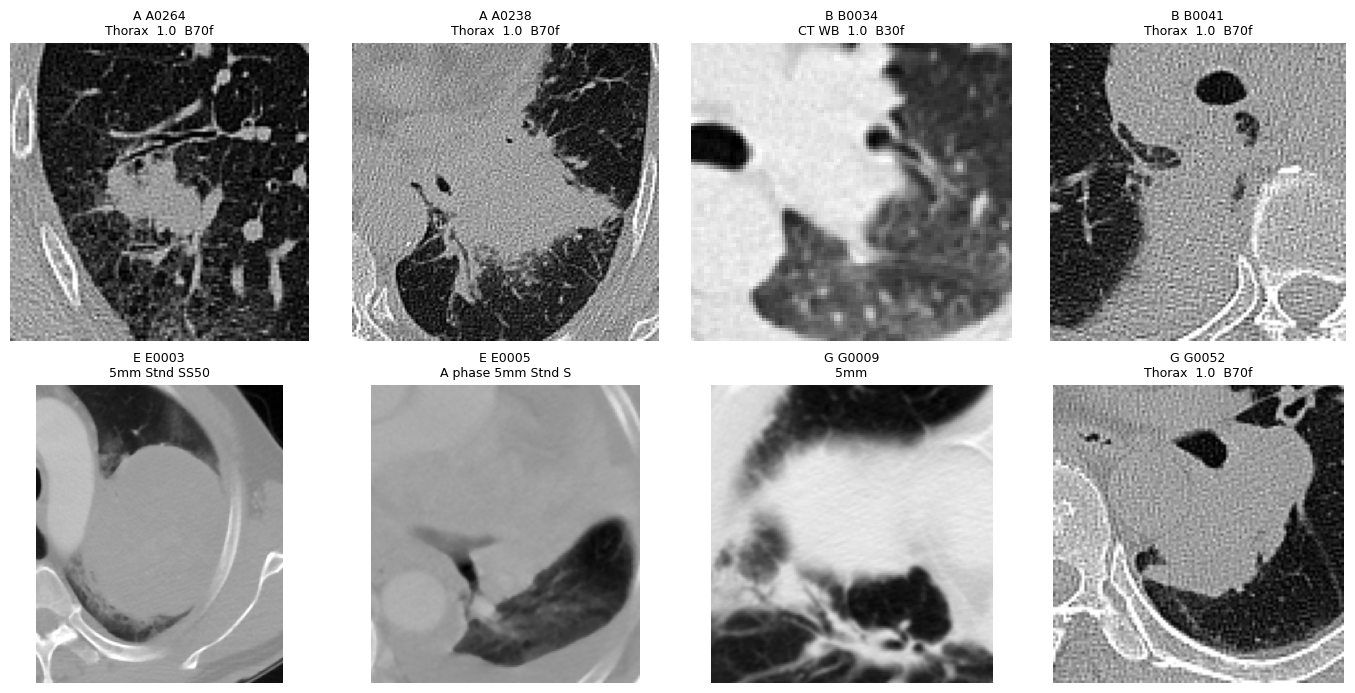

In [23]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, (cls, grp) in zip(axes.flat, [(c, g) for c in "ABEG" for g in [meta[meta["cls"] == c]] for _ in range(2)]):
    r = grp.sample(1).iloc[0]
    arr = np.load(OUT / f"{r['dicom_patient']}.npz")[r["key"]]
    img = (np.clip(arr, -1400, 700) + 1400) / 2100
    ax.imshow(img, cmap="gray")
    ax.set_title(f"{cls} {r['dicom_patient']}\n{r['series_desc'][:18]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [24]:
g = meta.groupby("sop_uid")["dicom_patient"].nunique()
print((g > 1).sum())
dups = meta[meta["sop_uid"].isin(g[g > 1].index)]
print(dups.groupby("dicom_patient").size())

0
Series([], dtype: int64)


In [25]:
print("xml_patient != dicom_patient:", (meta["xml_patient"] != meta["dicom_patient"]).sum())

meta2 = meta.drop_duplicates(["sop_uid", "obj_idx"]).copy()
meta2["cls"] = meta2["dicom_patient"].str[0]
print(len(meta), "->", len(meta2))
print(meta2.groupby("cls").agg(obiekty=("key", "count"), pacjenci=("dicom_patient", "nunique")))

meta2.to_csv("/content/drive/MyDrive/lung-ct/crops_meta_clean.csv", index=False)

xml_patient != dicom_patient: 117
20339 -> 20236
     obiekty  pacjenci
cls                   
A      13664       249
B       2088        38
E        201         5
G       4283        61


In [26]:
from sklearn.model_selection import train_test_split

pat = meta2.groupby("dicom_patient").agg(cls=("cls", "first"), n=("key", "count")).reset_index()
train, temp = train_test_split(pat, test_size=0.30, stratify=pat["cls"], random_state=42)
val, test = train_test_split(temp, test_size=0.50, stratify=temp["cls"], random_state=42)

split = {p: "train" for p in train["dicom_patient"]}
split.update({p: "val" for p in val["dicom_patient"]})
split.update({p: "test" for p in test["dicom_patient"]})
meta2["split"] = meta2["dicom_patient"].map(split)

print(meta2.groupby(["split", "cls"]).agg(obiekty=("key", "count"), pacjenci=("dicom_patient", "nunique")))
meta2.to_csv("/content/drive/MyDrive/lung-ct/crops_meta_split.csv", index=False)

           obiekty  pacjenci
split cls                   
test  A       2160        38
      B        574         5
      E         19         1
      G        849         9
train A       8879       174
      B       1378        27
      E        178         3
      G       2871        43
val   A       2625        37
      B        136         6
      E          4         1
      G        563         9
